# Sensitivity analysis of a cooled CSTR

**CHME 5137, homework after Lecture 15 (October 30, 2026).** In class we ran SALib on
someone else's model, the electric-car battery. Here you run the whole workflow yourself,
on a reactor.

*Written for 2026 by Claude Code (Claude Opus 5.5) and checked by Prof. West.*

---

A **continuous stirred-tank reactor (CSTR)** is a tank with liquid flowing in and out. A
stirrer keeps the contents well mixed, so the outgoing liquid has the same temperature and
composition as the liquid in the tank. Water flows through a separate jacket around the tank
and exchanges heat with it. At **steady state**, the temperature and composition stay constant
while liquid continues to flow.

The feed contains A, which can turn into B and back again ($\mathrm{A} \rightleftharpoons
\mathrm{B}$). The forward reaction releases heat, so we call it **exothermic**. The model
returns the reactor temperature $T$ in kelvin and the **conversion** $X$, the fraction of the
incoming A consumed. For example, $X=0.70$ means 70% of the A entering the tank is consumed.

- **Kinetics** tells us how fast the reaction proceeds. At low temperatures, little A reacts
  in the time the liquid spends in the tank (its *residence time*).
- **Equilibrium** tells us how far the reaction can go at a given temperature. Warming the
  reactor speeds up the approach to equilibrium, but higher temperatures favor A over B for
  this exothermic reaction, lowering the equilibrium conversion.

The model is provided. Start with the function's **Arguments** and **Returns** and the input
table below. The code comments explain how the model calculates conversion at each trial
temperature and finds where the heat entering and leaving the tank balances. The coolant
temperature `T_cool` is an input. The reactor temperature $T$ is an output that also depends
on the heat from the reaction, the feed temperature and the rate of heat transfer through the
jacket. Assume the reactor contents never boil at the temperatures considered. The jacket
contains water at atmospheric pressure.

### How to work

- **Use SALib 1.6.** The first code cell prints the installed version. See the repository
  README or the top of the Lecture 15 notebook for installation help.
- **Use the Lecture 15 examples.** The Morris and Sobol sections show how to sample inputs,
  run the model, and analyze the outputs in SALib.
- **Use `seed=2026`** wherever SALib takes a seed, so that your numbers can be compared with
  other people's.
- **Commit as you go.** After each numbered task, commit the `.ipynb` and its paired `.py`
  together and push. Before your final commit, use **Restart & Run All** and check the results.
- **Answer the questions in words**, in the markdown cells marked *Answer*. A sentence or
  two each.

In [1]:
from importlib.metadata import version
import time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [5, 3]
print('SALib', version('SALib'))

SALib 1.6.0


## The model

In [2]:
R = 8.314  # gas constant, J/mol/K


def cstr_steady_state(log10_A=9.1, Ea=80e3, dH=-60e3, dS=-146.0,
                      tau=600.0, T_feed=310.0, T_cool=365.0,
                      U=500.0, area=6.0, C_feed=3000.0,
                      rho_cp=1.7e6, W_stir=1000.0):
    """
    Steady state of a jacketed CSTR running the reversible, exothermic,
    first-order liquid-phase reaction A <=> B.

    Arguments, all in SI units:
        log10_A  log10 of the forward pre-exponential factor (A in 1/s)
        Ea       forward activation energy, J/mol
        dH       enthalpy of reaction, J/mol (negative: exothermic)
        dS       entropy of reaction, J/mol/K
        tau      residence time V/q, s
        T_feed   feed temperature, K
        T_cool   coolant temperature in the jacket, K (the jacket is well mixed)
        U        overall heat-transfer coefficient, W/m2/K
        area     heat-transfer area of the jacket, m2
        C_feed   concentration of A in the feed, mol/m3 (no B in the feed)
        rho_cp   volumetric heat capacity of the liquid, J/m3/K
        W_stir   power the stirrer puts into the liquid, W

    Returns:
        X        conversion of A, between 0 and 1
        T        reactor temperature, K
    """
    V = 1.0          # reactor volume, m3
    q = V / tau      # volumetric flow rate, m3/s

    # We don't know the reactor temperature yet, so try every temperature
    # from 250 K to 700 K, in steps of 0.1 K, all at once (NumPy arrays).
    T = np.linspace(250.0, 700.0, 4501)

    # Kinetics: the forward rate constant, from Arrhenius.
    k_f = 10**log10_A * np.exp(-Ea / (R * T))
    # Thermodynamics: K = k_f / k_r, and -RT ln K = dG = dH - T dS.
    K = np.exp(dS / R - dH / (R * T))
    k_r = k_f / K

    # Mole balance on A at steady state, in = out + reacted:
    #     q C_feed = q C_A + V (k_f C_A - k_r C_B),
    # with C_A = C_feed (1 - X) and C_B = C_feed X. Solved for X:
    X = k_f * tau / (1 + (k_f + k_r) * tau)

    # Energy balance at steady state, in watts. The reaction and stirrer add heat.
    # The feed and jacket terms remove heat when they are cooler than the reactor.
    # A warmer jacket adds heat (the U * area term is then negative).
    heat_released = -dH * q * C_feed * X + W_stir
    heat_removed = q * rho_cp * (T - T_feed) + U * area * (T - T_cool)
    imbalance = heat_released - heat_removed

    # A steady state is a temperature where the imbalance is zero. There can be
    # more than one (ignition and extinction). Take the lowest: it's the one the
    # reactor settles at when it's started up cold.
    crossings = np.nonzero(np.diff(np.sign(imbalance)))[0]
    i = crossings[0]
    # Interpolate between the grid points either side of that crossing.
    fraction = imbalance[i] / (imbalance[i] - imbalance[i + 1])
    T_ss = T[i] + fraction * (T[i + 1] - T[i])
    X_ss = X[i] + fraction * (X[i + 1] - X[i])
    return X_ss, T_ss

The **base case** is one reference set of inputs. The ranges describe where you will explore
the model. Some describe settings or designs you can choose and conditions that can change.
Others describe how uncertain you are about a property. For Sobol analysis here, the inputs
vary independently and equal-width intervals within each range are equally likely. For
`log10_A` this uniform distribution is on the log scale. The rankings depend on these choices.

| Input | Base | Range | Why that range |
|---|---|---|---|
| `log10_A` | 9.1 | 8.8 – 9.4 | *task 1(c)* |
| `Ea` (kJ/mol) | 80 | 78 – 82 | Fitted from rate data, ± 2 kJ/mol |
| `dH` (kJ/mol) | −60 | −65 – −55 | Heat-of-reaction measurements, ± 5 kJ/mol |
| `dS` (J/mol/K) | −146 | −153 – −139 | Estimate based on molecular structure |
| `tau` (s) | 600 | 300 – 1000 | The flow rate the pumps can deliver |
| `T_feed` (K) | 310 | 290 – 330 | The feed tank is outdoors: winter to summer |
| `T_cool` (K) | 365 | 320 – 373 | *task 1(c)* |
| `U` (W/m²/K) | 500 | 300 – 700 | Heat-transfer estimate, ± 40% |
| `area` (m²) | 6 | 4 – 8 | A design choice: the jacket size |
| `C_feed` (mol/m³) | 3000 | 2500 – 3500 | The feed specification |
| `rho_cp` (MJ/m³/K) | 1.7 | 1.6 – 1.8 | The solvent's density × heat capacity |
| `W_stir` (kW) | 1 | 0.5 – 2 | The stirrer motor |

`base` is a Python dictionary that maps each input name to its reference value. SALib's
`problem` dictionary lists the input names and their bounds in the same order. In the code,
use J/mol, J/m³/K and W for the quantities listed in kJ/mol, MJ/m³/K and kW in the table.

In [3]:
problem = {
    'num_vars': 12,
    'names': ['log10_A', 'Ea', 'dH', 'dS', 'tau', 'T_feed', 'T_cool',
              'U', 'area', 'C_feed', 'rho_cp', 'W_stir'],
    'bounds': [[8.8, 9.4],         # log10_A: see task 1(c)
               [78e3, 82e3],       # Ea, J/mol
               [-65e3, -55e3],     # dH, J/mol
               [-153.0, -139.0],   # dS, J/mol/K
               [300.0, 1000.0],    # tau, s
               [290.0, 330.0],     # T_feed, K
               [320.0, 373.0],     # T_cool, K: see task 1(c)
               [300.0, 700.0],     # U, W/m2/K
               [4.0, 8.0],         # area, m2
               [2500.0, 3500.0],   # C_feed, mol/m3
               [1.6e6, 1.8e6],     # rho_cp, J/m3/K
               [500.0, 2000.0]],   # W_stir, W
}
base = dict(log10_A=9.1, Ea=80e3, dH=-60e3, dS=-146.0, tau=600.0, T_feed=310.0,
            T_cool=365.0, U=500.0, area=6.0, C_feed=3000.0, rho_cp=1.7e6, W_stir=1000.0)

## Task 1. The base case, one input at a time

**(a) Worked example.** Run the model with the reference inputs. `**base` passes the values
by name, as if you had written `log10_A=9.1, Ea=80000, ...` inside the function call. The
function returns two numbers. The assignment below stores the conversion in `X0` and the
reactor temperature in `T0`.

In [4]:
X0, T0 = cstr_steady_state(**base)
print(f'Base case: X = {X0:.3f}, T = {T0:.1f} K')

Base case: X = 0.731, T = 376.1 K


**(b)** Vary the coolant temperature from 320 to 400 K in 1 K steps, with everything else
at its base value. For each temperature, copy `base` and change `T_cool` in the copy.
For example, `dict(base, T_cool=340)` makes a copy with a coolant temperature of 340 K.

Plot both conversion and reactor temperature against `T_cool`. Mark 373 K, approximately
the boiling point of water at atmospheric pressure. Label the region above 373 K as **model
extrapolation**. The equations there still return numbers for liquid coolant, even though water
would boil. Which coolant temperature at or below 373 K gives the highest conversion? Why does
the conversion rise and then fall?

Highest conversion at or below 373 K: T_coo; = 367 K, X = 0.732


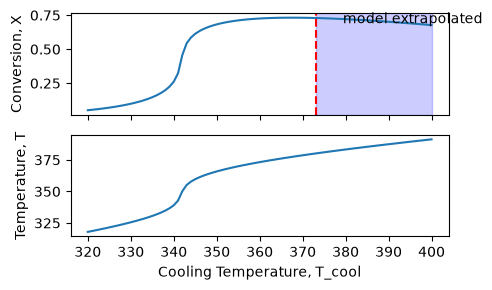

<Figure size 500x300 with 0 Axes>

In [8]:
T_cool_sweep = np.arange(320, 401)
X_sweep = []
T_sweep = []
for T_cool in T_cool_sweep:
   X, T = cstr_steady_state(**dict(base, T_cool=T_cool))
   X_sweep.append(X)
   T_sweep.append(T)

X_sweep = np.array(X_sweep)
T_sweep = np.array(T_sweep)

allowed = T_cool_sweep <= 373.0
best = np.argmax(X_sweep[allowed])
print(f"Highest conversion at or below 373 K: " f"T_coo; = {T_cool_sweep[allowed][best]} K, X = {X_sweep[allowed][best]:.3f}")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

ax1.plot(T_cool_sweep, X_sweep)
ax1.set_ylabel("Conversion, X")

ax2.plot(T_cool_sweep, T_sweep)
ax2.set_ylabel("Temperature, T")
ax2.set_xlabel("Cooling Temperature, T_cool")

for ax in (ax1, ax2):
    ax.axvline(373, color = 'red', linestyle = '--')
    ax.axvspan(373,400, color = 'blue', alpha = 0.2)

    ax1.text(0.72, 0.9, "model extrapolated", transform = ax1.transAxes)
    plt.tight_layout()
    plt.show()




**Answer:**

**(c)** The available cooling water can be as cold as 320 K. Explain why the upper end of
the `T_cool` range is a physical limit for this model. For `log10_A`, by what factor do you
multiply or divide $A$ when `log10_A` moves by 0.3 from its base value? Why is a log scale a
convenient way to express that uncertainty?

The upper end of the T_cool range (373K) is a physical limit for this model because water boils at 373K at atmospheric pressure. The model assumes the water is liquid, however at or above this temperature the water would behave as vapor. For log10_A, multiply or divide A by 10^0.3 when log10_A moves by 0.3 from its base value depending on whether the 0.3 is being added to or subtracted from log10_A. A log scale is a convenient way to express that uncertainty because its expresses the uncertainty as a factor rather than a fixed amount. 

## Task 2. Running the model on a sample, and local sensitivities

**(a)** SALib gives us a two-dimensional array. Each row is a set of inputs for one model run.
Its columns follow the order in `problem['names']`, which matches the order of the model's
arguments. In the example below, `*first_row` passes those values to the model in that order.
The model uses a temperature array internally to solve for one reactor temperature for that
row. In the vehicle-to-grid example from class, the model could evaluate all rows at once.

Complete `run_model(sample)`. Loop over the rows and collect the results into two NumPy
arrays, one for conversion and one for reactor temperature. Keep the outputs in the same
order as the input rows so you can pass them to SALib later. Test with `test_sample[:5]` and
check that you get five values in each array and that the first pair matches the example.
Time the first 1000 rows using `time.perf_counter()` before and after the call. Use the elapsed
time to estimate how long 10 000 and 100 000 runs would take. Report those estimates and
explain how you got them in your answer.

In [ ]:
from SALib.sample import sobol as sobol_sample

test_sample = sobol_sample.sample(problem, 128, calc_second_order=False, seed=2026)
first_row = test_sample[0]
X_first, T_first = cstr_steady_state(*first_row)
print(f'First row: X = {X_first:.3f}, T = {T_first:.1f} K')

In [ ]:
def run_model(sample):
    """Return one conversion and reactor temperature per row."""
    # Loop over the rows, call the model, and collect its two outputs.
    # Return the two collections as NumPy arrays.


# Test the first five rows and time the first 1000 here.

**Answer:**

**(b) Local sensitivity.** At the base case, compute the normalised local sensitivity
$$S_i^\mathrm{local} = \frac{\partial \ln X}{\partial \ln |p_i|}
\approx \frac{\ln X(p_i(1+\delta)) - \ln X(p_i(1-\delta))}{2\delta}$$
of the conversion to each input $p_i$. Use $\delta = 0.01$. For each input, make two copies
of `base`. Multiply that input by 1.01 in one copy and by 0.99 in the other. Run the model with
each copy and use the two conversions in the formula. For negative inputs such as `dH` and
`dS`, multiplying by 1.01 makes the value more negative. The sign stays fixed, so the
derivative is with respect to the log of the input's magnitude.

A sensitivity of +2 means that increasing the magnitude of the input by 1% increases $X$ by
about 2% near the base case. For `log10_A`, apply the change to the input `log10_A` itself.
A 1% increase there multiplies $A$ by about 1.23 at the base case.

Print a table sorted by the absolute size of the sensitivities. Which inputs matter most by
this measure? What does it say about `T_cool`?

**Answer:**

## Task 3. Morris screening

Morris screens inputs by taking one-input-at-a-time steps from different starting points.
Each route through the input grid is called a *trajectory*. Use 100 trajectories, 4 levels
and `seed=2026`. Count the rows of your sample to find the number of model runs. Use
`run_model` and pass the conversions to the Morris analyzer.

Print μ (average signed effect), μ\* (average absolute effect) and σ (spread of the effects)
for each input. Make the two Morris plots (`horizontal_bar_plot` and `covariance_plot`). See
the Morris section of Lecture 15 for the plotting calls.

Which inputs rank highest by μ\*, and which are candidates for fixing? Which have σ larger
than μ\*, and what does that suggest about how their effects vary across the input ranges?

In [ ]:
from SALib.sample import morris as morris_sample
from SALib.analyze import morris as morris_analyze
from SALib.plotting import morris as morris_plot

# your code here


**Answer:**

## Task 4. Sobol indices

**(a)** Sobol indices describe how much of the variation in conversion is associated with
each input. $S_1$ measures the contribution of one input alone. $S_T$ adds that contribution
and every interaction involving the input. $S_2$ measures the contribution of a pair beyond
the two inputs' individual effects.

Use $N = 1024$ (the base sample size), `calc_second_order=True` for both sampling and
analysis, and `seed=2026`. Save the sample as `sobol_X` and the two model outputs as
`sobol_Y` (conversion) and `sobol_T` (reactor temperature) for reuse. How many rows are in
the sample? Print $S_1$ and $S_T$ for each input, largest $S_T$ first. Report the approximate
95% interval as $S_T$ ± `ST_conf`. SALib returns the half-width in `ST_conf`.

In [ ]:
from SALib.analyze import sobol as sobol_analyze

# your code here


**(b)** Answer in words:

1. Rank the inputs by $S_T$. Does it agree with the Morris ranking from task 3? Morris used
   far fewer runs: was it good enough to tell you which inputs matter?
2. Which input has the biggest gap between $S_T$ and $S_1$? What does that gap mean?
3. Compare with your local sensitivities from task 2(b). Pick the input where local and
   global disagree most, and explain why. (Look back at your plot from task 1(b).)
4. Find the largest estimated second-order index above the diagonal in `Si['S2']`. Use the
   corresponding entry in `Si['S2_conf']` as the ± half-width. Does the interval include zero?
   What physical reason could make those two inputs interact?

**Answer:**

## Task 5. Can we fix the least influential inputs?

Factor fixing means holding some inputs at a constant value to reduce the number you have to
vary. Choose the inputs with estimated $S_T < 0.03$ using the unrounded values. Fix them at
their base values, then check how closely the predictions agree.

1. Take your Sobol sample from task 4, set the fixed columns to their base values, and run
   the model again on the same rows. (Copy the array first: `reduced = sobol_X.copy()`.)
2. Plot the reduced model's conversion against the full model's, one point per row, with
   the line $y = x$.
3. Use the formula below to compute the **agreement score** for the paired predictions.
   $1 - \sum (X_\mathrm{full} - X_\mathrm{reduced})^2 / \sum (X_\mathrm{full} - \bar X_\mathrm{full})^2$.
   The score is 1 for exact agreement and 0 if the squared error equals that of predicting
   the full-model mean for every row. Compare it with $1 - \sum S_T$ of the inputs you fixed.
   Treat that number as a rough check. For example, a single interaction between two fixed
   inputs contributes to both of their total indices.
4. Find the largest absolute difference between the two predictions for any row. Report both
   conversions for that row. Given the plot and this difference, when would you trust the
   reduced model?

**Answer:**

## Task 6. What should you measure better? It depends how you run the reactor

You've designed the reactor and are considering three coolant temperatures. At each setting,
the six uncertain properties are `log10_A`, `Ea`, `dH`, `dS`, `U` and `rho_cp`. You have money
for one set of measurements.

**(a)** Make a new `problem` with those six inputs and their original ranges. Generate one
Sobol sample with $N = 1024$ and `seed=2026`. Set `calc_second_order=False` in both sampling
and analysis. Run the same sample at 325 K, 350 K and 373 K (the model's near-boiling limit).
At each temperature, vary the six sampled inputs and keep the remaining inputs at their base
values. Print a table of total Sobol indices for conversion with one row per input and one
column per coolant temperature.

Each sample row now holds only six of the model's twelve inputs. For each run start with a
fresh `inputs = base.copy()`, then set `inputs['T_cool']` to the chosen temperature. Match
the six names with the six values in the row, update `inputs`, and pass `**inputs` to the model.
Keep the conversion for Sobol analysis.

**(b)** Which property would you prioritize for measurement with cold coolant? With coolant
near boiling? Explain the change using kinetics and equilibrium. Which property would you
give the lowest measurement priority across these three settings?

**Answer:**

**(c)** Would you run the reactor at the coolant temperature that gave the highest conversion
in Task 1? Give two reasons for caution, including a physical effect the model leaves out.
Use your sweep to estimate how many percentage points of conversion you'd lose by lowering
the coolant temperature 10 K from that optimum.

**Answer:**

---

### Stretch (optional)

- **Scatter plots.** Plot $X$ against each input for the Sobol sample, as in class. Which
  inputs show a clear trend? Can you see `T_cool`'s optimum?
- **Reactor temperature.** Repeat task 4 for the reactor temperature (`sobol_T`) instead of
  the conversion. Which inputs control the temperature, and how is that different?
- **Convergence.** Repeat task 4(a) with $N$ = 128, 256 and 512. How much do the $S_T$ values
  and their intervals change? What $N$ would you have been happy with?
- **More than one steady state.** The model takes the lowest steady state when there's more than
  one. For how many rows of your Sobol sample is there more than one? Where in the input space
  are they? How does that help explain the largest difference you found in task 5?